Setup & Load Master Analytical Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

# Load Master Table
df = pd.read_csv(
    PROCESSED_DATA_PATH / "sales_master_analytical.csv",
    parse_dates=["Order Date", "Delivery Date"]
)

# Styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print(f"Loaded master dataset: {df.shape[0]:,d} rows, {df.shape[1]} columns")
print(f"Active Date Window: {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")

Loaded master dataset: 62,884 rows, 40 columns
Active Date Window: 2016-01-01 to 2021-02-20


Strategic Question 1 & 6 — Revenue Drivers & Strategic Product Portfolio

PARETO ANALYSIS: 708 of 2492 products (28.4%) generate 80% of revenue.


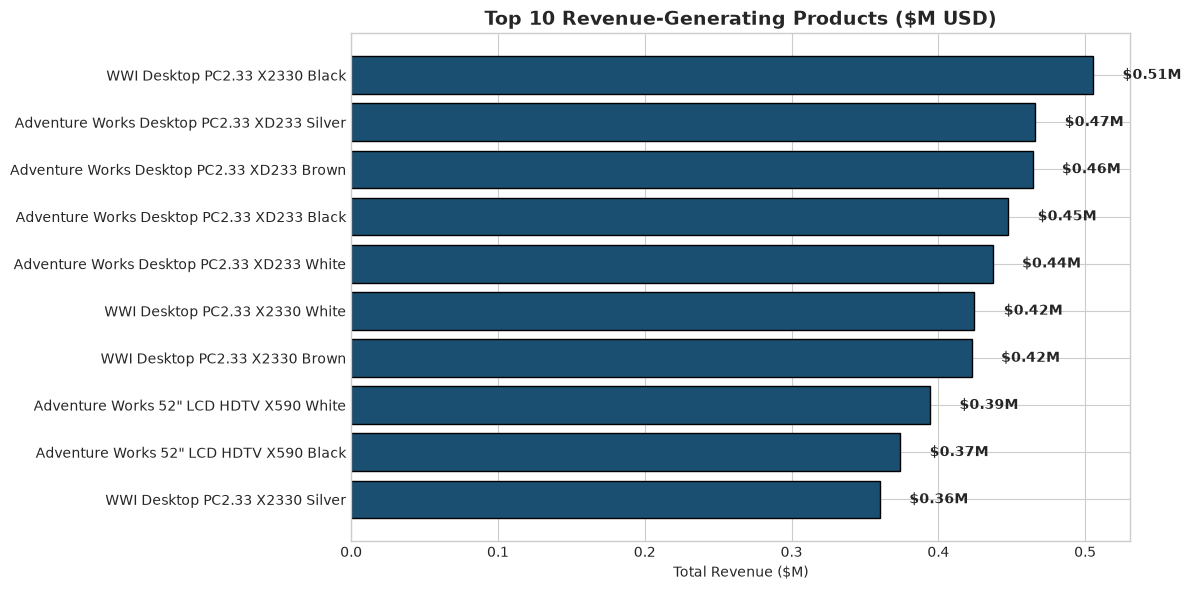

,Product Name,Category,Total_Units,Total_Revenue,Total_Profit,Avg_Margin_Pct
431,Adventure Works Desktop PC2.33 XD233 White,Computers,451,437019.0,292225.45,66.87
420,Adventure Works Desktop PC2.33 XD233 Black,Computers,462,447678.0,299352.90,66.87
426,Adventure Works Desktop PC2.33 XD233 Brown,Computers,479,464151.0,310368.05,66.87
414,Adventure Works Desktop PC2.33 XD233 Silver,Computers,481,466089.0,311663.95,66.87
442,WWI Desktop PC2.33 X2330 Black,Computers,550,505450.0,337986.00,66.87


In [2]:
# 1. Product Aggregations
product_perf = (
    df.groupby(["ProductKey", "Product Name", "Category", "Subcategory"])
    .agg(
        Total_Units=("Quantity", "sum"),
        Total_Revenue=("Revenue_USD", "sum"),
        Total_Profit=("Profit_USD", "sum"),
        Avg_Margin_Pct=("Profit_Margin_Pct", "mean")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

# Pareto Calculation
product_perf["Cum_Revenue"] = product_perf["Total_Revenue"].cumsum()
product_perf["Cum_Revenue_Pct"] = (product_perf["Cum_Revenue"] / product_perf["Total_Revenue"].sum()) * 100

top_80_count = (product_perf["Cum_Revenue_Pct"] <= 80).sum()
total_products = len(product_perf)

print("=" * 60)
print(f"PARETO ANALYSIS: {top_80_count} of {total_products} products ({top_80_count/total_products*100:.1f}%) generate 80% of revenue.")
print("=" * 60)

# 2. Visualize Top 10 Revenue Drivers
fig, ax = plt.subplots(figsize=(12, 6))
top10 = product_perf.head(10).sort_values("Total_Revenue", ascending=True)

bars = ax.barh(top10["Product Name"], top10["Total_Revenue"] / 1e6, color="#1b4f72", edgecolor="black")
ax.set_title("Top 10 Revenue-Generating Products ($M USD)", fontsize=14, fontweight="bold")
ax.set_xlabel("Total Revenue ($M)")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.02, bar.get_y() + bar.get_height()/2, f"${w:.2f}M", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

display(top10[["Product Name", "Category", "Total_Units", "Total_Revenue", "Total_Profit", "Avg_Margin_Pct"]].tail(5))

Strategic Question 2 — Store Optimization & Sales Density Benchmark

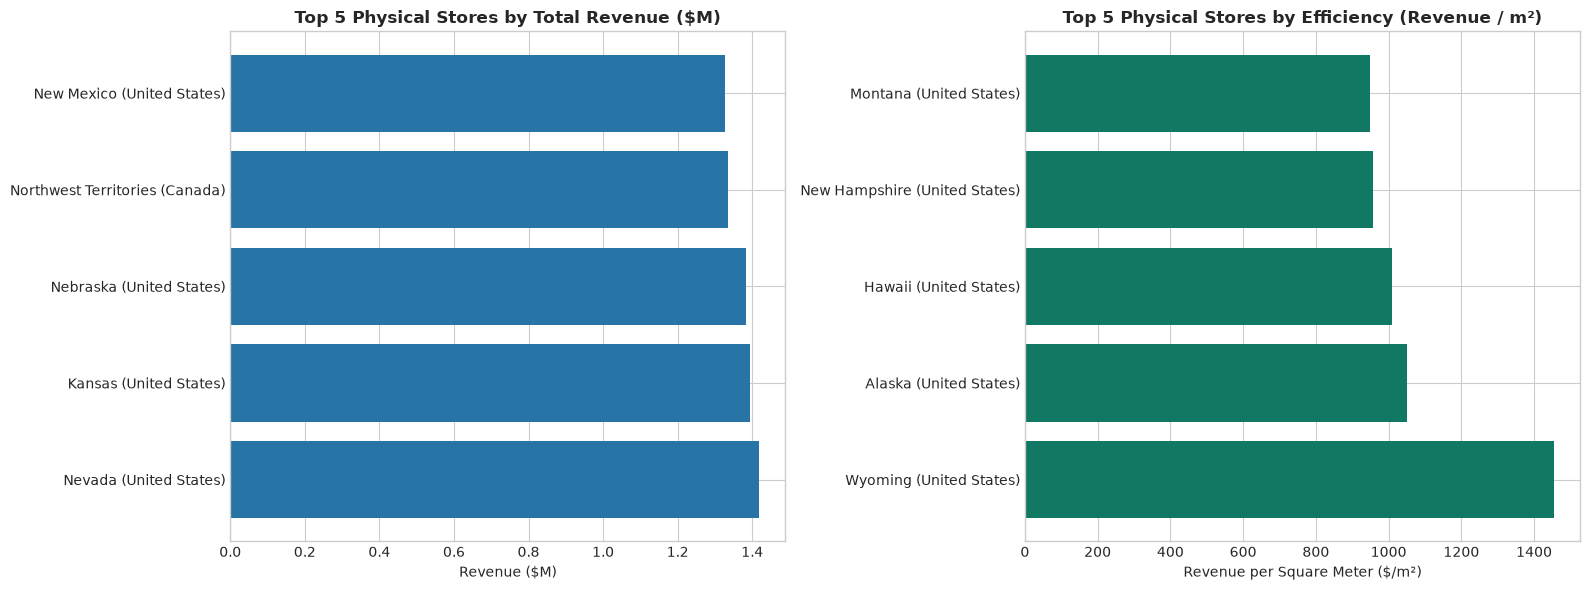

Store Density Summary:


,StoreKey,Store_Country,Store_State,Square Meters,Total_Orders,Total_Revenue,Total_Profit,Sales_Per_Sqm,Profit_Per_Sqm
56,66,United States,Wyoming,840.0,545,1220964.38,723190.21,1453.53,860.94
37,43,United States,Alaska,1190.0,558,1250255.14,741093.00,1050.63,622.77
40,47,United States,Hawaii,1120.0,582,1130742.94,655657.70,1009.59,585.41
48,56,United States,New Hampshire,1260.0,525,1207253.73,707631.60,958.14,561.61
45,53,United States,Montana,1260.0,534,1193921.14,696761.99,947.56,552.99
54,64,United States,Washington DC,1330.0,566,1259350.98,745283.99,946.88,560.36
24,29,Italy,Enna,1000.0,417,913856.35,538542.06,913.86,538.54
6,9,Canada,Northwest Territories,1500.0,658,1336150.06,774757.55,890.77,516.51
44,51,United States,Maine,1295.0,581,1130592.31,659826.29,873.04,509.52
7,10,Canada,Nunavut,1210.0,528,1043185.80,606299.20,862.14,501.07


In [7]:
# Exclude Online (StoreKey 0) to evaluate physical retail efficiency
store_perf = (
    df[df["StoreKey"] != 0]
    .groupby(["StoreKey", "Store_Country", "Store_State", "Square Meters"])
    .agg(
        Total_Orders=("Order Number", "nunique"),
        Total_Revenue=("Revenue_USD", "sum"),
        Total_Profit=("Profit_USD", "sum")
    )
    .reset_index()
)

# Sales Density Metric
store_perf["Sales_Per_Sqm"] = (store_perf["Total_Revenue"] / store_perf["Square Meters"]).round(2)
store_perf["Profit_Per_Sqm"] = (store_perf["Total_Profit"] / store_perf["Square Meters"]).round(2)

# Top 5 by Revenue vs Top 5 by Efficiency
top_rev_stores = store_perf.sort_values("Total_Revenue", ascending=False).head(5)
top_eff_stores = store_perf.sort_values("Sales_Per_Sqm", ascending=False).head(5)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Top Stores by Total Revenue
axes[0].barh(top_rev_stores["Store_State"] + " (" + top_rev_stores["Store_Country"] + ")", 
             top_rev_stores["Total_Revenue"] / 1e6, color="#2874a6")
axes[0].set_title("Top 5 Physical Stores by Total Revenue ($M)", fontweight="bold")
axes[0].set_xlabel("Revenue ($M)")

# Plot 2: Top Stores by Sales Density ($/m²)
axes[1].barh(top_eff_stores["Store_State"] + " (" + top_eff_stores["Store_Country"] + ")", 
             top_eff_stores["Sales_Per_Sqm"], color="#117864")
axes[1].set_title("Top 5 Physical Stores by Efficiency (Revenue / m²)", fontweight="bold")
axes[1].set_xlabel("Revenue per Square Meter ($/m²)")

plt.tight_layout()
plt.show()

print("Store Density Summary:")
display(store_perf.sort_values("Sales_Per_Sqm", ascending=False).head(10))

Strategic Question 3 — Time-Series Trend & Structural Shift

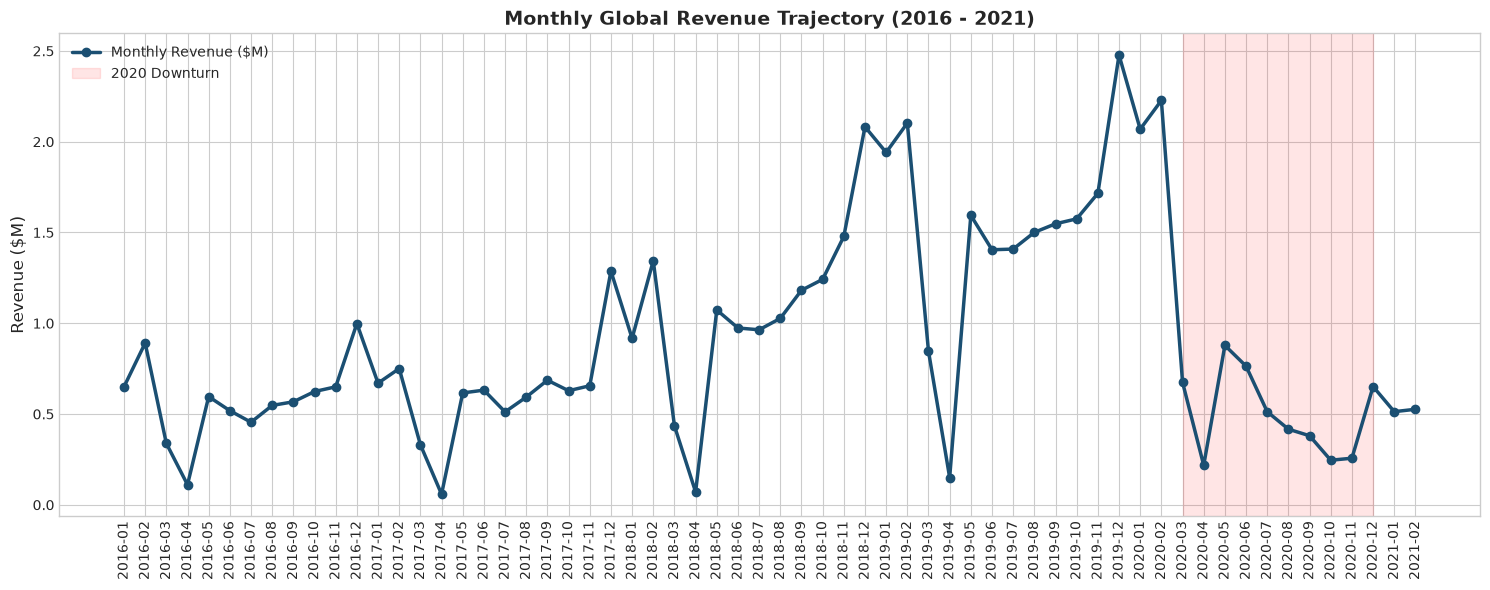

Observation Note: 2021 data ends on 2021-02-20. The apparent decline in 2021 is due to an incomplete fiscal year.


In [4]:
# Monthly aggregation
monthly_trend = (
    df.groupby("Order_YearMonth")
    .agg(
        Revenue=("Revenue_USD", "sum"),
        Profit=("Profit_USD", "sum"),
        Orders=("Order Number", "nunique")
    )
    .reset_index()
)

monthly_trend["MoM_Growth_%"] = (monthly_trend["Revenue"].pct_change() * 100).round(2)

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(monthly_trend["Order_YearMonth"], monthly_trend["Revenue"] / 1e6, 
         marker="o", color="#1b4f72", linewidth=2.5, label="Monthly Revenue ($M)")
ax1.set_title("Monthly Global Revenue Trajectory (2016 - 2021)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Revenue ($M)", fontsize=12)
ax1.tick_params(axis="x", rotation=90)

# Highlight COVID / Decline Window
ax1.axvspan("2020-03", "2020-12", color="red", alpha=0.1, label="2020 Downturn")

ax1.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Verify the date cutoff in 2021
last_date = df[df["Order_Year"] == 2021]["Order Date"].max()
print(f"Observation Note: 2021 data ends on {last_date.date()}. The apparent decline in 2021 is due to an incomplete fiscal year.")

Strategic Question 4 — Underperformers & Delisting Matrix

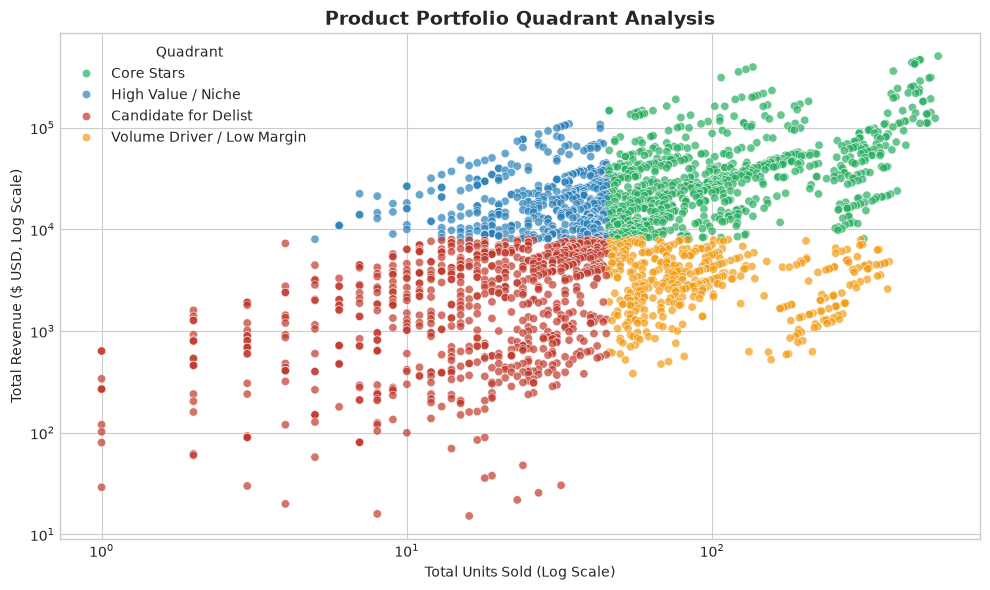

Total Delisting Candidates Identified: 805 products


,Product Name,Category,Subcategory,Total_Units,Total_Revenue,Avg_Margin_Pct
919,SV USB Data Cable E600 Silver,Computers,Computers Accessories,16,15.20,49.47
924,SV USB Sync Charge Cable E700 Silver,Computers,Computers Accessories,8,15.92,49.25
2419,Litware 80mm Dual Ball Bearing Case Fan E1001 ...,Home Appliances,Fans,4,19.96,49.10
920,SV USB Data Cable E600 Grey,Computers,Computers Accessories,23,21.85,49.47
917,SV USB Data Cable E600 Pink,Computers,Computers Accessories,27,25.65,49.47
2405,"Litware 16"" White Oscillating Stand Fan E701 W...",Home Appliances,Fans,1,29.09,49.02
2413,Litware 120mm Blue LED Case Fan E901 Black,Home Appliances,Fans,3,29.97,49.05
918,SV USB Data Cable E600 Black,Computers,Computers Accessories,32,30.40,49.47
921,SV USB Sync Charge Cable E700 Blue,Computers,Computers Accessories,18,35.82,49.25
922,SV USB Sync Charge Cable E700 Black,Computers,Computers Accessories,19,37.81,49.25


In [5]:
# Quadrant Classification based on medians
median_rev = product_perf["Total_Revenue"].median()
median_units = product_perf["Total_Units"].median()

product_perf["Quadrant"] = "Maintain"
product_perf.loc[(product_perf["Total_Revenue"] < median_rev) & (product_perf["Total_Units"] < median_units), "Quadrant"] = "Candidate for Delist"
product_perf.loc[(product_perf["Total_Revenue"] >= median_rev) & (product_perf["Total_Units"] < median_units), "Quadrant"] = "High Value / Niche"
product_perf.loc[(product_perf["Total_Revenue"] < median_rev) & (product_perf["Total_Units"] >= median_units), "Quadrant"] = "Volume Driver / Low Margin"
product_perf.loc[(product_perf["Total_Revenue"] >= median_rev) & (product_perf["Total_Units"] >= median_units), "Quadrant"] = "Core Stars"

delist_candidates = product_perf[product_perf["Quadrant"] == "Candidate for Delist"].sort_values("Total_Revenue")

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=product_perf,
    x="Total_Units",
    y="Total_Revenue",
    hue="Quadrant",
    palette={"Core Stars": "#27ae60", "High Value / Niche": "#2980b9", 
             "Volume Driver / Low Margin": "#f39c12", "Candidate for Delist": "#c0392b"},
    alpha=0.7,
    ax=ax
)
ax.set_title("Product Portfolio Quadrant Analysis", fontsize=14, fontweight="bold")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Total Units Sold (Log Scale)")
ax.set_ylabel("Total Revenue ($ USD, Log Scale)")

plt.tight_layout()
plt.show()

print(f"Total Delisting Candidates Identified: {len(delist_candidates)} products")
display(delist_candidates[["Product Name", "Category", "Subcategory", "Total_Units", "Total_Revenue", "Avg_Margin_Pct"]].head(10))

Strategic Question 5 — Customer Purchasing Dynamics

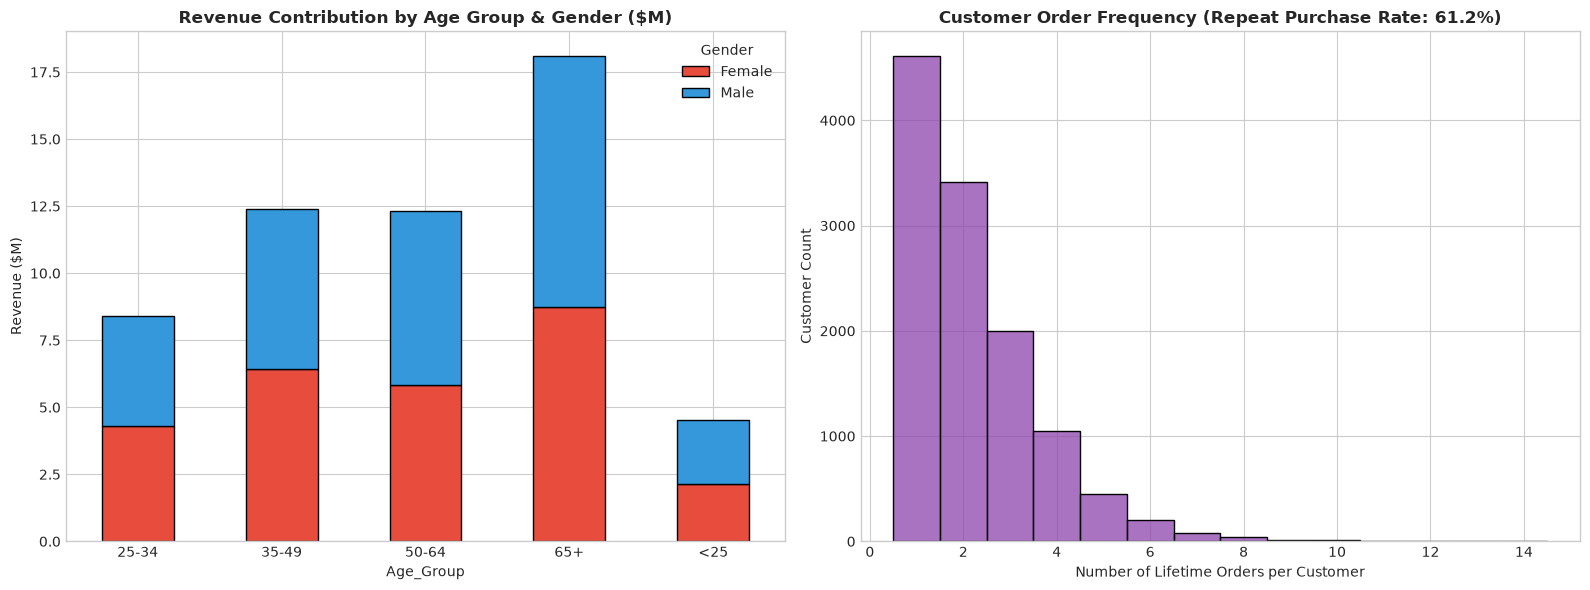

In [6]:
# 1. Revenue by Age Group and Gender
cust_demo = (
    df.groupby(["Age_Group", "Gender"])["Revenue_USD"]
    .sum()
    .unstack()
    / 1e6
)

# 2. Customer Order Frequency (Retention)
orders_per_customer = df.groupby("CustomerKey")["Order Number"].nunique()
repeat_rate = (orders_per_customer > 1).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Demographic Revenue
cust_demo.plot(kind="bar", stacked=True, ax=axes[0], color=["#e74c3c", "#3498db"], edgecolor="black")
axes[0].set_title("Revenue Contribution by Age Group & Gender ($M)", fontweight="bold")
axes[0].set_ylabel("Revenue ($M)")
axes[0].tick_params(axis="x", rotation=0)

# Plot 2: Customer Purchase Frequency Distribution
sns.histplot(orders_per_customer, bins=15, discrete=True, ax=axes[1], color="#8e44ad")
axes[1].set_title(f"Customer Order Frequency (Repeat Purchase Rate: {repeat_rate:.1f}%)", fontweight="bold")
axes[1].set_xlabel("Number of Lifetime Orders per Customer")
axes[1].set_ylabel("Customer Count")

plt.tight_layout()
plt.show()